<a href="https://colab.research.google.com/github/dhhung98-bot/Chess/blob/main/lesson03_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 第 3 堂：替局面打分數

上週寫的「不送車」下法，車一次都沒丟，可是 88% 的盤都拖到時間到，還是贏不了。

問題在哪？它只知道「不要犯錯」，卻不知道「往哪裡走比較容易贏」。就像考選擇題只會刪掉明顯錯的選項，剩下的卻不知道選哪個。

所以今天要幫電腦做一件事：**替每個局面打分數**。分數高，代表從這裡下下去比較容易贏。有了分數，電腦就知道該往分數高的地方走。

今天會做這幾件事：

1. 把一盤棋從頭到尾記下來
2. 算出每一步「之後總共還能拿幾分」，而且越後面的分數要打折
3. 用「多下幾盤、取平均」的方法，算出一個局面值幾分
4. 把分數畫在棋盤上，看看哪裡分數高
5. 寫一個「大部分時間選最好的，偶爾隨便試試」的函式

上課方式跟上週一樣：**先猜再跑**、**換你講**、**改壞看看**，下課前錄 2 分鐘。

## 1. 準備

下面這格是前兩週寫好的程式：棋盤、裁判 `evaluate`、三種下法（亂下、能將死就將死、不送車）。

只多了一個小功能：`reset` 現在可以指定「從哪個局面開始下」，等一下會用到。

直接執行就好。

In [ ]:
!pip install -q chess

import chess
import random
import matplotlib.pyplot as plt


def random_krk_board():
    while True:
        board = chess.Board(None)
        wk, wr, bk = random.sample(chess.SQUARES, 3)
        board.set_piece_at(wk, chess.Piece(chess.KING, chess.WHITE))
        board.set_piece_at(wr, chess.Piece(chess.ROOK, chess.WHITE))
        board.set_piece_at(bk, chess.Piece(chess.KING, chess.BLACK))
        board.turn = chess.WHITE
        if board.is_valid() and not board.is_game_over():
            return board


class KRKEnv:
    def __init__(self, max_steps=50, step_penalty=0.01):
        self.max_steps = max_steps
        self.step_penalty = step_penalty

    def reset(self, fen=None):
        if fen is None:
            self.board = random_krk_board()   # 沒指定：隨機擺一個局面
        else:
            self.board = chess.Board(fen)     # 有指定：從這個局面開始
        self.steps = 0
        self.done = False
        return self.get_state()

    def get_state(self):
        wk = self.board.king(chess.WHITE)
        bk = self.board.king(chess.BLACK)
        rooks = self.board.pieces(chess.ROOK, chess.WHITE)
        wr = list(rooks)[0] if rooks else None
        return (wk, wr, bk)

    def legal_actions(self):
        return list(self.board.legal_moves)

    def is_terminal(self):
        return self.done

    def step(self, move):
        self.board.push(move)
        self.steps += 1
        if self.board.is_checkmate():
            self.done = True
            return self.get_state(), 1.0, True
        if self.board.is_stalemate():
            self.done = True
            return self.get_state(), -1.0, True
        self.board.push(random.choice(list(self.board.legal_moves)))
        if self.board.is_insufficient_material():
            self.done = True
            return self.get_state(), -1.0, True
        if self.steps >= self.max_steps:
            self.done = True
            return self.get_state(), -self.step_penalty, True
        return self.get_state(), -self.step_penalty, False


def game_result(env):
    if env.board.is_checkmate():
        return "win"
    if env.board.is_stalemate():
        return "stalemate"
    if env.board.is_insufficient_material():
        return "rook lost"
    return "timeout"


def evaluate(policy, n=3000, seed=0, max_steps=50, step_penalty=0.01):
    random.seed(seed)
    env = KRKEnv(max_steps=max_steps, step_penalty=step_penalty)
    count = {"win": 0, "stalemate": 0, "rook lost": 0, "timeout": 0}
    total = 0
    for i in range(n):
        env.reset()
        G = 0
        while not env.is_terminal():
            state, reward, done = env.step(policy(env))
            G += reward
        count[game_result(env)] += 1
        total += G
    return count, round(count["win"] / n * 100, 1), round(total / n, 3)


def random_policy(env):
    return random.choice(env.legal_actions())


def find_mate(env):
    for move in env.legal_actions():
        env.board.push(move)
        mate = env.board.is_checkmate()
        env.board.pop()
        if mate:
            return move
    return None


def rook_is_safe(board):
    rooks = board.pieces(chess.ROOK, chess.WHITE)
    if not rooks:
        return False
    sq = list(rooks)[0]
    return (not board.is_attacked_by(chess.BLACK, sq)) or board.is_attacked_by(chess.WHITE, sq)


def safe_policy(env):
    move = find_mate(env)
    if move is not None:
        return move
    good = []
    for move in env.legal_actions():
        env.board.push(move)
        if rook_is_safe(env.board) and not env.board.is_stalemate():
            good.append(move)
        env.board.pop()
    return random.choice(good) if good else random.choice(env.legal_actions())

print("準備好了")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
準備好了


## 2. 把一盤棋記下來

以前我們只看「最後贏了沒」，就像考完試只看總分。今天要把整張考卷攤開來看：每一題（每一步）發生了什麼。

下面這個函式會下一盤棋，同時用兩個 list 當筆記：

- `states`：每一步**走之前**，三個棋子在哪裡
- `rewards`：每一步走完，拿到幾分（大部分是 −0.01，最後一步可能是 +1 或 −1）

這格直接執行，重點是看懂它記了什麼。

In [ ]:
def play_and_record(env, policy, fen=None):
    env.reset(fen)
    states = []
    rewards = []
    while not env.is_terminal():
        states.append(env.get_state())          # 先記下：走之前棋子在哪
        state, reward, done = env.step(policy(env))
        rewards.append(reward)                  # 再記下：這一步拿幾分
    return states, rewards

**先猜再跑**：用「不送車」下一盤。`states` 和 `rewards` 這兩個 list 會一樣長嗎？最後一個分數最可能是多少？

我猜：

In [ ]:
random.seed(1)
env = KRKEnv()
states, rewards = play_and_record(env, safe_policy)

print("一共走了幾步：", len(states), len(rewards))
print("前 3 步的局面：", states[:3])
print("最後 3 步的分數：", rewards[-3:])
print("這盤的結果：", game_result(env))

一共走了幾步： 50 50
前 3 步的局面： [(60, 48, 26), (52, 48, 17), (61, 48, 10)]
最後 3 步的分數： [-0.01, -0.01, -0.01]
這盤的結果： timeout


**換你講**：`(60, 48, 26)` 這三個數字分別是什麼？

## 3. 打折：越後面的分數越不值錢

我們想知道：**站在某一步，這一步到底好不好？**

只看這一步自己拿幾分是不夠的。例如將死的前一步，它自己只拿 −0.01，可是它其實是很棒的一步，因為下一步就贏了。

所以要看的是：**這一步，加上之後每一步，總共拿幾分。**

不過，越後面才拿到的分數，要打越多折。為什麼？

想像有人說：「今天給你 100 元，或一年後給你 100 元，你選哪個？」大部分人選今天，因為一年後的事很難說，說不定根本拿不到。下棋也一樣：下一步就贏，很確定；十步以後才可能贏，中間什麼事都可能發生。

打幾折呢？我們用一個希臘字母 **γ**（唸「伽瑪」）來代表。今天用 γ = 0.9，也就是：**每往後一步，就打九折**。

### 先用手算

一盤只有三步，每一步的分數依序是：−0.01、−0.01、+1（最後一步將死）。

- 站在最後一步：後面沒有了，總分就是 **1**
- 站在第二步：自己的 −0.01，加上「後面那一步的總分」打九折 → −0.01 + 0.9 × 1 = ？
- 站在第一步：自己的 −0.01，加上「後面那一步的總分」打九折 → −0.01 + 0.9 × (上一行算出來的數) = ？

發現了嗎？**從最後一步往前算**最輕鬆，因為每一步都要用到「後面那一步已經算好的數字」。

我算出來：第二步 = ＿＿＿，第一步 = ＿＿＿

### 練習 1：把手算寫成程式

`discounted_returns(rewards, gamma)` 要回傳一個 list，裡面是「站在每一步，之後的總分（打過折）」。

做法跟手算一模一樣：

- `reversed(rewards)` 會從最後一個分數開始，倒著一個一個拿
- `G` 記的是「後面那一步算好的總分」，一開始還沒有，所以是 0
- 每拿到一個分數 `r`，這一步的總分就是：`G = r + gamma * G`，算完把它存進 `returns`

因為是倒著算的，存起來的順序也是倒的，所以最後要再用 `reversed` 轉回正的順序。

In [ ]:
def discounted_returns(rewards, gamma=0.9):
    G = 0
    returns = []
    for r in reversed(rewards):
        # TODO: 算出這一步的總分 G
        G = r + gamma * G

        # TODO: 把 G 存進 returns
        returns.append(G)

    return list(reversed(returns))


print(discounted_returns([-0.01, -0.01, 1.0]))   # 跟你手算的一樣嗎？

[0.791, 0.89, 1.0]


**改壞看看**：把打折的程度改成 0 和 1，各跑一次。

- γ = 0：每往後一步就打「零折」，等於後面的分數完全不算。第一步的總分會是多少？
- γ = 1：完全不打折，後面的分數跟現在一樣重要。第一步的總分會是多少？

In [ ]:
print("γ = 0  ", discounted_returns([-0.01, -0.01, 1.0], gamma=0))
print("γ = 0.9", discounted_returns([-0.01, -0.01, 1.0], gamma=0.9))
print("γ = 1  ", discounted_returns([-0.01, -0.01, 1.0], gamma=1))

γ = 0   [-0.01, -0.01, 1.0]
γ = 0.9 [0.791, 0.89, 1.0]
γ = 1   [0.98, 0.99, 1.0]


**換你講**：如果電腦的 γ 是 0，它會變成什麼個性？如果是 1 呢？

## 4. 一個局面值幾分？

現在要替局面打分數：**從這個局面開始下，平均總共能拿幾分**。

這個分數有個正式名字叫「**價值**」，課本常寫成 **V(s)**：V 是 value（價值），s 是 state（局面）。看到 V(s)，就唸成「局面 s 值幾分」。

問題來了：電腦沒有直覺，它怎麼知道一個局面值幾分？

答案很直接：**從這個局面開始，多下幾盤，看平均拿幾分。** 就像你想知道一家新開的餐廳好不好吃，最簡單的方法就是去吃很多次，再取平均。

這種「多試幾次、取平均」的方法，有一個很帥的名字：**蒙地卡羅方法**。

### 蒙地卡羅是什麼？

**名字怎麼來的**：蒙地卡羅（Monte Carlo）是歐洲小國摩納哥的一個地方，以賭場出名。賭博靠運氣，這個方法靠的也是「隨機」，所以就用它來命名。

**怎麼發明的**：1940 年代，有位數學家叫烏拉姆（Stanislaw Ulam），生病在家休養時玩撲克牌接龍。他想知道「接龍成功的機率是多少」，可是用數學算非常複雜，算不出來。後來他想到：**乾脆玩一百次，數數看成功幾次就好了。** 那時剛好有了早期的電腦，可以很快地「玩」很多次，這個想法就變成一個正式的方法，幫科學家解決很多算不出來的問題。

**一句話記住它**：**算不出來的東西，就隨機試很多次來估計。試越多次，越準。**（跟第 1 週的擲硬幣是同一個道理。）

**現在哪裡在用**：天氣預報（模擬很多種天氣可能怎麼變）、銀行估投資風險、電玩遊戲的 AI，連打敗世界圍棋冠軍的 AlphaGo 也用到這個想法。

### 小實驗：用丟石頭算出圓周率

先用一個跟下棋無關的例子，感受一下這個方法有多神奇。

想像一個邊長 1 的正方形，裡面畫四分之一個圓（半徑是 1）。往正方形裡**隨便丟很多顆小石頭**：

- 正方形的面積是 1
- 四分之一圓的面積是 π ÷ 4
- 所以，落在圓裡的石頭大約佔 π ÷ 4
- 把這個比例乘以 4，就能估出 π

整個過程完全不用知道 π 是多少，只要會「隨機丟石頭」和「數數」就好。

**先猜再跑**：丟 100 顆、1000 顆、1 萬顆、10 萬顆，哪一次最接近 3.14159？丟 100 顆大概會差多少？

我猜：

In [ ]:
random.seed(0)

for n in [100, 1000, 10000, 100000]:
    inside = 0
    for i in range(n):
        x = random.random()          # 石頭落點的 x，0 到 1 之間
        y = random.random()          # 石頭落點的 y，0 到 1 之間
        if x * x + y * y <= 1:       # 離左下角的距離 ≤ 1，就是落在圓裡
            inside += 1
    print("丟", n, "顆，落在圓裡", inside, "顆，估出 π ≈", 4 * inside / n)

丟 100 顆，落在圓裡 76 顆，估出 π ≈ 3.04
丟 1000 顆，落在圓裡 780 顆，估出 π ≈ 3.12
丟 10000 顆，落在圓裡 7861 顆，估出 π ≈ 3.1444
丟 100000 顆，落在圓裡 78711 顆，估出 π ≈ 3.14844


把 1000 顆石頭畫出來看看：落在圓裡和圓外的，用不同顏色。

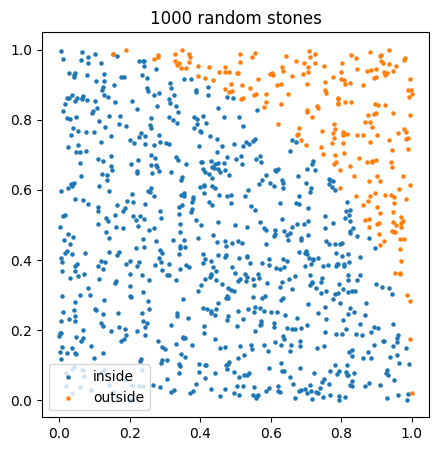

In [ ]:
random.seed(0)
in_x, in_y, out_x, out_y = [], [], [], []
for i in range(1000):
    x, y = random.random(), random.random()
    if x * x + y * y <= 1:
        in_x.append(x)
        in_y.append(y)
    else:
        out_x.append(x)
        out_y.append(y)

plt.figure(figsize=(5, 5))
plt.scatter(in_x, in_y, s=5, label="inside")
plt.scatter(out_x, out_y, s=5, label="outside")
plt.legend()
plt.title("1000 random stones")
plt.show()

**換你講**：為什麼丟越多顆，估出來的 π 越準？等一下我們要算「局面值幾分」，跟丟石頭哪裡很像？

### 回到棋盤

剛剛是「丟很多顆石頭，看落在圓裡的比例」；現在換成「**從同一個局面下很多盤，看平均拿幾分**」。道理完全一樣。

我們準備了三個局面，都是輪到白方走：

A 一步就能將死


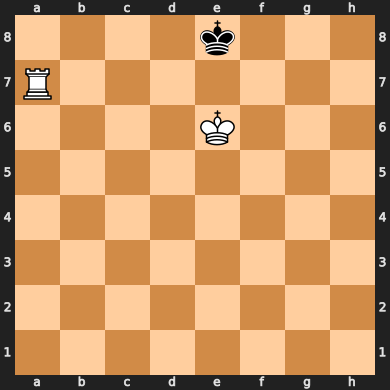

B 黑王在邊上


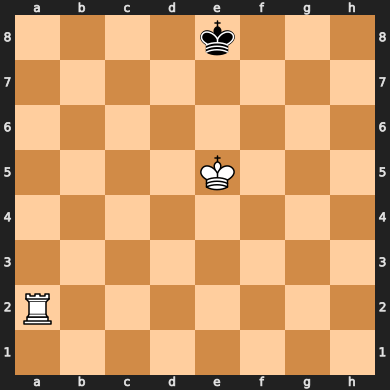

C 黑王在中間


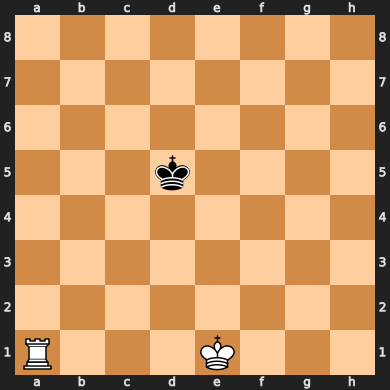

In [ ]:
positions = {
    "A 一步就能將死": "4k3/R7/4K3/8/8/8/8/8 w - - 0 1",
    "B 黑王在邊上":   "4k3/8/8/4K3/8/8/R7/8 w - - 0 1",
    "C 黑王在中間":   "8/8/8/3k4/8/8/8/R3K3 w - - 0 1",
}

for name, fen in positions.items():
    print(name)
    display(chess.Board(fen))

**先猜再跑**：用「不送車」的下法，從這三個局面各下 300 盤。哪個局面的分數最高？哪個最低？

我猜：最高是＿＿，最低是＿＿

因為：

### 練習 2：算出一個局面值幾分

寫 `estimate_value(fen, policy, n)`：從 `fen` 這個局面開始下 `n` 盤，回傳平均拿幾分。

（`fen` 是一串記錄棋盤的文字，第 1 週看過。在這裡把它當成「局面的代號」就好。）

拆成四個小步驟，每一步都用得到前面寫好的東西：

1. 用 `play_and_record` 從這個局面下一盤，拿到 `rewards`
2. 用 `discounted_returns` 算出每一步之後的總分
3. 我們只要**第一步**那一個，因為第一步就是我們想知道的那個局面，所以取 `[0]`
4. 把它加進 `total`，下完 `n` 盤再除以 `n`

In [ ]:
def estimate_value(fen, policy, n=300, gamma=0.9, seed=0):
    random.seed(seed)
    env = KRKEnv()
    total = 0
    for i in range(n):
        # TODO: 從 fen 下一盤，拿到 rewards
        states, rewards = play_and_record(env, policy, fen)
        # TODO: 算出每一步之後的總分，把第一步的那個加進 total
        total += discounted_returns(rewards, gamma)[0]
        pass
    return round(total / n, 3)

In [ ]:
for name, fen in positions.items():
    print(name, "→ 不送車下法：", estimate_value(fen, safe_policy))

A 一步就能將死 → 不送車下法： 1.0
B 黑王在邊上 → 不送車下法： -0.01
C 黑王在中間 → 不送車下法： -0.092


**再猜一次**：如果換成**亂下**，局面 A 還會是分數最高的嗎？大概幾分？

我猜：

In [ ]:
for name, fen in positions.items():
    print(name, "→ 亂下：", estimate_value(fen, random_policy))

A 一步就能將死 → 亂下： -0.207
B 黑王在邊上 → 亂下： -0.238
C 黑王在中間 → 亂下： -0.246


**換你講**：同樣是局面 A，為什麼「不送車」算出來是 1，「亂下」卻是負的？所以一個局面值幾分，除了看局面本身，還跟什麼有關？

## 5. 把分數畫在棋盤上

剛剛只算了三個局面。可是王車殺單王總共有大約 17 萬種局面，每個都下 300 盤，要下到天荒地老。

所以我們先偷懶一下：**只看黑王站在哪一格**，不管白王和白車在哪。例如黑王在 a1 的所有局面，全部放在一起取平均。棋盤只有 64 格，這樣只要算 64 個平均就好。

做法：

1. 用「不送車」下 3000 盤
2. 每一步都記下兩件事：黑王在哪一格、這一步之後的總分
3. 每一格把分數加起來，再除以出現的次數，就是那一格的平均
4. 把 64 個平均畫成 8×8 的圖，**顏色越亮，分數越高**

這種用顏色深淺表示數字大小的圖，叫做**熱力圖**。

**先猜再跑**：你覺得黑王站在哪裡時，顏色會最亮？中間、邊線、還是角落？為什麼？

我猜：

In [ ]:
random.seed(0)
env = KRKEnv()
total = [0.0] * 64     # 每一格：分數加起來
count = [0] * 64       # 每一格：黑王出現幾次

for i in range(3000):
    states, rewards = play_and_record(env, safe_policy)
    returns = discounted_returns(rewards, 0.9)
    for state, G in zip(states, returns):     # 一步一步拿出「局面」和「之後的總分」
        black_king = state[2]                 # 局面的第 3 個數字是黑王的位置
        total[black_king] += G
        count[black_king] += 1

value = [total[sq] / count[sq] if count[sq] > 0 else 0 for sq in range(64)]
print("算好了。黑王在中間 e4 的平均：", round(value[chess.E4], 3), "；在角落 a1 的平均：", round(value[chess.A1], 3))

算好了。黑王在中間 e4 的平均： -0.074 ；在角落 a1 的平均： -0.028


畫成圖。小提醒：畫出來的圖，第一列在最上面，所以要把棋盤的第 8 列放在最上面，從第 8 列畫到第 1 列。

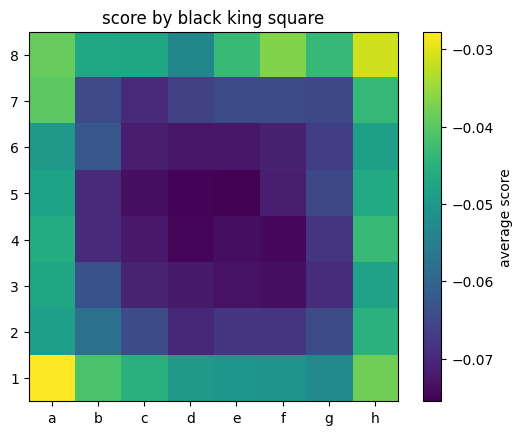

In [ ]:
grid = []
for rank in range(7, -1, -1):           # 從第 8 列畫到第 1 列
    row = [value[chess.square(file, rank)] for file in range(8)]
    grid.append(row)

plt.imshow(grid, cmap="viridis")
plt.colorbar(label="average score")
plt.xticks(range(8), list("abcdefgh"))
plt.yticks(range(8), list("87654321"))
plt.title("score by black king square")
plt.show()

**換你講**：圖上最亮的是哪裡？為什麼？如果你是白方，你會想把黑王趕到哪裡？

## 6.（加分題）要下幾盤才夠？

丟石頭時，丟越多顆越準。算局面的分數也一樣嗎？我們拿局面 C，分別下 10 盤、100 盤、500 盤，每種換三個種子各算一次，看結果穩不穩。

**先猜再跑**：只下 10 盤時，三次算出來的分數會差多少？下 500 盤呢？

我猜：

In [ ]:
fen_c = positions["C 黑王在中間"]
for n in [10, 100, 500]:
    results = [estimate_value(fen_c, safe_policy, n=n, seed=s) for s in range(3)]
    print("每次下", n, "盤，三次的結果：", results)

每次下 10 盤，三次的結果： [-0.099, -0.09, -0.097]
每次下 100 盤，三次的結果： [-0.093, -0.087, -0.092]
每次下 500 盤，三次的結果： [-0.09, -0.091, -0.091]


**換你講**：這跟剛剛丟石頭算 π 有什麼關係？

## 7. 偶爾亂試一下

假設電腦已經知道每一步大概值幾分。它應該**永遠**選分數最高的那一步嗎？

想想你點手搖飲：每次都點同一杯，永遠不會踩雷，但也永遠不會知道菜單上有沒有更好喝的。偶爾試一杯新的，可能難喝，也可能找到新的最愛。

電腦學下棋也一樣。它一開始估的分數不一定準，如果永遠只走「它以為最好」的那步，可能一輩子都發現不了更好的走法。所以要**偶爾亂試一下**。

這個方法叫 **ε-greedy**：

- ε 也是希臘字母，唸「艾普西龍」，在這裡代表「亂試的機率」，例如 0.1 就是 10%
- greedy 是英文的「貪心」，代表「選目前看起來最好的」
- 合起來就是：**大部分時間貪心，偶爾亂試**

程式怎麼寫？`random.random()` 會給一個 0 到 1 之間的隨機數字。如果這個數字比 ε 小，就亂選一步；不然就選最好的。ε = 0.1 時，大約每 10 次會有 1 次亂選。

### 練習 3

In [ ]:
def epsilon_greedy(best_move, actions, eps):
    # TODO: 產生一個 0 到 1 的隨機數字

    #       比 eps 小 → 從 actions 隨便選一個
    if random.random() < eps:
        return random.choice(actions)
    #       不然     → 回傳 best_move
    else: return best_move


**先猜再跑**：假設有 20 個選擇，最好的是 0 號。用 ε = 0.1 選 10000 次，「沒選到 0 號」會佔幾 %？剛好 10% 嗎？

我猜：

In [ ]:
random.seed(0)
actions = list(range(20))       # 20 個選擇：0 到 19
not_best = 0
for i in range(10000):
    if epsilon_greedy(0, actions, 0.1) != 0:
        not_best += 1
print("沒選到最好的：", not_best / 100, "%")

沒選到最好的： 9.63 %


**換你講**：為什麼會比 10% 少一點？

## 8.（加分題）亂試多少比較好？

把「偶爾亂試」加到「不送車」的下法上：有 ε 的機率亂走一步，其他時候照「不送車」走。比較 ε = 0、0.1、0.3 的勝率。

In [ ]:
def make_eps_safe_policy(eps):
    # 這是一個「做下法的工廠」：給它 eps，它交給你一個新的下法
    def policy(env):
        return epsilon_greedy(safe_policy(env), env.legal_actions(), eps)
    return policy

**先猜再跑**：亂試的機率越高，勝率一定越低嗎？

我猜：

In [ ]:
for eps in [0, 0.1, 0.3]:
    count, win_rate, avg = evaluate(make_eps_safe_policy(eps), n=1000)
    print("亂試機率", eps, "→ 勝率", win_rate, "%", count)

亂試機率 0 → 勝率 12.7 % {'win': 127, 'stalemate': 0, 'rook lost': 0, 'timeout': 873}
亂試機率 0.1 → 勝率 11.8 % {'win': 118, 'stalemate': 0, 'rook lost': 92, 'timeout': 790}
亂試機率 0.3 → 勝率 10.6 % {'win': 106, 'stalemate': 2, 'rook lost': 268, 'timeout': 624}


## 9. 這個方法的問題

「多下幾盤取平均」很好懂，但要用在整個殘局上，有三個麻煩：

- 局面有大約 17 萬種
- 每個局面都要下好幾百盤，分數才會準（就像丟石頭要丟很多顆）
- 而且下法一改，所有分數都要重算（因為分數跟誰在下有關）

**換你講**：如果每個局面下 500 盤，總共要下幾盤？照今天的速度（3000 盤大約 1 分鐘），要跑多久？

下週要學一個聰明很多的方法：**不用等一盤下完，每走一步就修正一點點**，而且會直接記住「在這個局面，走哪一步比較好」。它叫做 **Q-learning**。

## 10. 存到 GitHub

1. 在畫熱力圖那格的 `plt.show()` 上面加一行 `plt.savefig("heatmap.png")`，重新執行。左邊的檔案欄會出現 `heatmap.png`，把它下載下來。
2. 「檔案 → 在 GitHub 中儲存副本」，檔名 `lesson03.ipynb`，說明寫清楚做了什麼。
3. 到 GitHub 的專案頁面，按「Add file → Upload files」，把 `heatmap.png` 傳上去。
4. 編輯 README，在上週的表格下面加這段：

```
## 第 3 堂：替局面打分數

![heatmap](heatmap.png)

黑王在邊線和角落時，白方的分數比較高。
```

## 下課前：錄 2 分鐘

1. 今天做了什麼？
2. 哪裡最難？你是怎麼弄懂的（或是還沒懂）？
3. 用你自己的話說：一個局面值幾分，要怎麼算？為什麼它跟「誰在下」有關？

## 作業（大約 2 到 3 小時）

每做完一題就存一次 GitHub。

### 第 1 題：換一個打折的程度

把熱力圖那格裡的 `0.9` 改成 `0.5` 和 `0.99`，各畫一張圖，跟 0.9 那張比一比。用兩三句話寫下差在哪裡，為什麼。

### 第 2 題：亂下的熱力圖

把熱力圖那格裡的 `safe_policy` 換成 `random_policy`，再畫一張。為什麼這張圖的顏色比較平均？

### 第 3 題：自己挑一個局面

用 [lichess 棋盤編輯器](https://lichess.org/editor) 擺一個王車殺單王的局面（輪到白方走），複製畫面下方那串 FEN，用 `estimate_value` 算它值幾分。再擺一個你覺得「比較不好贏」的局面算一次。結果跟你想的一樣嗎？

### 第 4 題：想一想

如果電腦只知道每個**局面**值幾分，它要怎麼決定**下一步**要走哪裡？會遇到什麼麻煩？寫想法就好，下週一開始聽你講。

正在計算 gamma = 0.5...


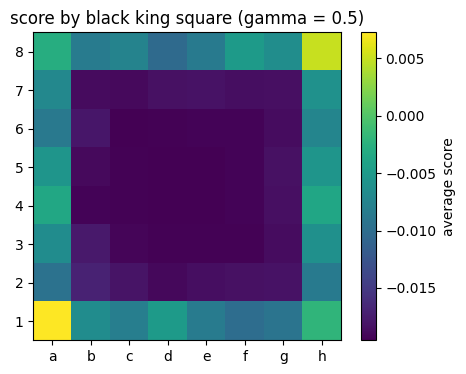

正在計算 gamma = 0.99...


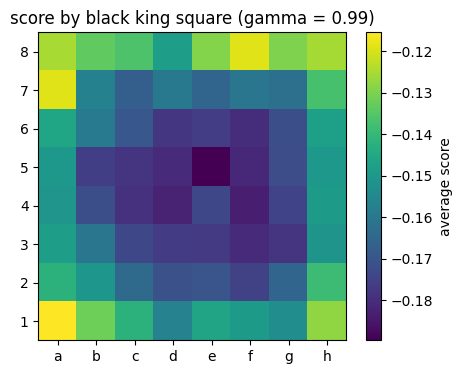

In [ ]:
import numpy as np
import chess
import matplotlib.pyplot as plt
import random

# 定義計算與繪圖的函式
def plot_heatmap_for_gamma(gamma, title):
    total = [0.0] * 64
    count = [0] * 64

    # 重新用 safe_policy 跑 3000 盤來估算
    random.seed(0)
    env = KRKEnv()
    for i in range(3000):
        states, rewards = play_and_record(env, safe_policy)
        returns = discounted_returns(rewards, gamma)
        for state, G in zip(states, returns):
            black_king = state[2]
            total[black_king] += G
            count[black_king] += 1

    value = [total[sq] / count[sq] if count[sq] > 0 else 0 for sq in range(64)]

    grid = []
    for rank in range(7, -1, -1):
        row = [value[chess.square(file, rank)] for file in range(8)]
        grid.append(row)

    plt.figure(figsize=(5, 4))
    plt.imshow(grid, cmap="viridis")
    plt.colorbar(label="average score")
    plt.xticks(range(8), list("abcdefgh"))
    plt.yticks(range(8), list("87654321"))
    plt.title(title)
    plt.show()

# 繪製 gamma = 0.5 的熱力圖
print("正在計算 gamma = 0.5...")
plot_heatmap_for_gamma(0.5, "score by black king square (gamma = 0.5)")

# 繪製 gamma = 0.99 的熱力圖
print("正在計算 gamma = 0.99...")
plot_heatmap_for_gamma(0.99, "score by black king square (gamma = 0.99)")

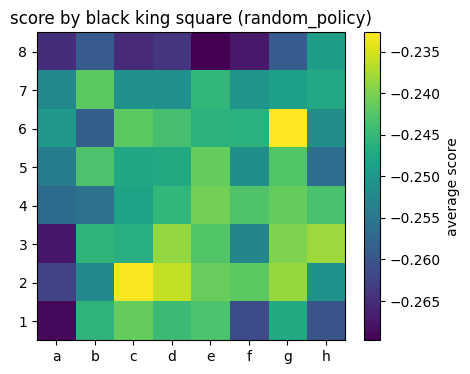

In [ ]:
import numpy as np
import chess
import matplotlib.pyplot as plt
import random

# 2. 亂下的熱力圖：使用 random_policy 代替 safe_policy
random.seed(0)
env = KRKEnv()
total = [0.0] * 64     # 每一格：分數加起來
count = [0] * 64       # 每一格：黑王出現幾次

for i in range(3000):
    states, rewards = play_and_record(env, random_policy)
    returns = discounted_returns(rewards, 0.9)
    for state, G in zip(states, returns):
        black_king = state[2]
        total[black_king] += G
        count[black_king] += 1

value = [total[sq] / count[sq] if count[sq] > 0 else 0 for sq in range(64)]

grid = []
for rank in range(7, -1, -1):
    row = [value[chess.square(file, rank)] for file in range(8)]
    grid.append(row)

plt.figure(figsize=(5, 4))
plt.imshow(grid, cmap="viridis")
plt.colorbar(label="average score")
plt.xticks(range(8), list("abcdefgh"))
plt.yticks(range(8), list("87654321"))
plt.title("score by black king square (random_policy)")
plt.show()

In [ ]:
# 第 3 題寫在這裡

第 4 題寫在這裡：